# **Assignment 2 - Satellite Image Classification Using Machine Learning**
### **GMFM350**

**Author:** Simen Roko Krogstie

### Imports

In [1]:
import time, os, pathlib
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy.stats import randint, loguniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    RandomizedSearchCV
)

### Data paths

In [2]:
# Path to data folder relative to this notebook
DATA_PATH = pathlib.Path().cwd() / "data"

# Path to image data and labels
img = DATA_PATH / "S2B_MSIL2A_20230606T103629_N0509_R008_T32VPM_20230606T121204.vrt"
lable = DATA_PATH / "training_data.tif"

### Data exploration

In [3]:
# Open the 10-band image lazily (dimensions: band, y, x)
im = rioxarray.open_rasterio(img)

# Band order in the VRT
features = ["B2", "B3", "B4", "B8", "B5", "B6", "B7", "B8A", "B11", "B12"]
im = im.assign_coords(band=features)
im

<xarray.DataArray (band: 10, y: 10980, x: 10980)> Size: 2GB
[1205604000 values with dtype=uint16]
Coordinates:
  * band         (band) <U3 120B 'B2' 'B3' 'B4' 'B8' ... 'B7' 'B8A' 'B11' 'B12'
  * y            (y) float64 88kB 6.7e+06 6.7e+06 6.7e+06 ... 6.59e+06 6.59e+06
  * x            (x) float64 88kB 6e+05 6e+05 6e+05 ... 7.098e+05 7.098e+05
    spatial_ref  int64 8B 0
Attributes:
    STATISTICS_APPROXIMATE:    YES
    STATISTICS_MAXIMUM:        7860
    STATISTICS_MEAN:           1366.5741708993
    STATISTICS_MINIMUM:        538
    STATISTICS_STDDEV:         304.17602932869
    STATISTICS_VALID_PERCENT:  100
    scale_factor:              1.0
    add_offset:                0.0

In [4]:
# Min and max values of image bands
print(im.min(dim=['x', 'y']).data, im.max(dim=['x', 'y']).data)

[  1 675 648 687 680 655 670 736 959 985] [19312 18320 17536 16769 17239 16969 16880 16716 16198 16108]


In [5]:
# Training labels on the same grid as the image
lab = rioxarray.open_rasterio(lable).squeeze("band", drop=True)

# Class codes in the training data and their names
class_names = {10: "Built-up", 20: "Arable land", 30: "Forest", 50: "Open field", 60: "Mire", 81: "Water"}

# Checking that the image data and labels line up
print("Image:", im.shape, im.dtype, "| resolution:", im.rio.resolution(), "| CRS:", im.rio.crs)
print("Labels:", lab.shape, lab.dtype)

Image: (10, 10980, 10980) uint16 | resolution: (10.0, -10.0) | CRS: EPSG:32632
Labels: (10980, 10980) uint8


In [6]:
# Slicing the original image to only the western half of the tile to reduce compute since I am runnning locally
half = dict(x=slice(0, im.sizes["x"] // 2))
im = im.isel(**half)
lab = lab.isel(**half)
print("Image:", dict(im.sizes), "| Labels:", dict(lab.sizes))

Image: {'band': 10, 'y': 10980, 'x': 5490} | Labels: {'y': 10980, 'x': 5490}


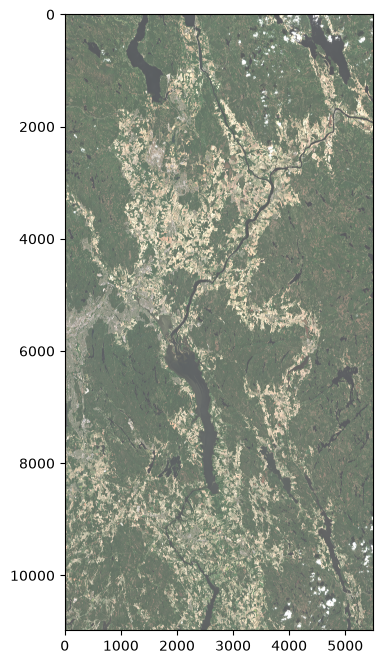

In [ ]:
# Plotting the sliced image for visual inspection
rgb = im.sel(band=["B4", "B3", "B2"]).transpose("y", "x", "band")
plt.figure(figsize=(8, 8))
plt.imshow((rgb / 3000).clip(0, 1))

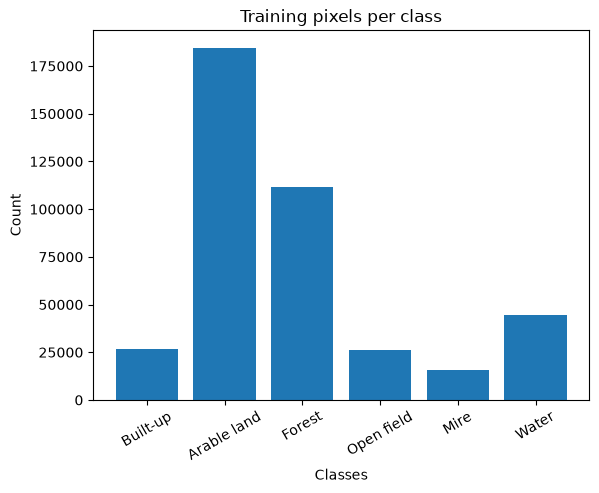

In [ ]:
# Histogram plot of the number of training pixels per class
values, counts = np.unique(lab.values, return_counts=True)
plt.bar([class_names[v] for v in values[1:]], counts[1:])
plt.xlabel("Classes")
plt.ylabel("Count")
plt.title("Training pixels per class")
plt.xticks(rotation=30)
plt.show()

### Training data

In [9]:
# Indices of the training pixels with a valid class value
lab_np = lab.values
indices = np.argwhere(lab_np > 0)
print(indices.shape)

# Extract the features X and the class labels y, one band at a time
X = np.empty((len(indices), len(features)), dtype=np.uint16)
for i, band in enumerate(features):
    X[:, i] = im.sel(band=band).values[indices[:, 0], indices[:, 1]]
y = lab_np[indices[:, 0], indices[:, 1]]

df = pd.DataFrame(X, columns=features)
df["class"] = y
print(df.shape)
df.head()

(409197, 2)
(409197, 11)


,B2,B3,B4,B8,B5,B6,B7,B8A,B11,B12,class
0,1708,1908,1720,4780,2260,3741,4461,4591,3035,2350,10
1,1285,1286,1256,1418,1552,1921,2039,2075,1928,1626,81
2,1258,1213,1183,1272,1179,1201,1253,1214,1179,1114,81
3,1256,1204,1169,1242,1179,1201,1253,1214,1179,1114,81
4,1218,1209,1155,1217,1187,1230,1223,1166,1126,1089,81


In [10]:
# Encode the class codes
le = LabelEncoder()
df["class_en"] = le.fit_transform(df["class"])

# Class names in the same order as the encoded values
classnames = np.array([class_names[c] for c in le.classes_])
df.head()

,B2,B3,B4,B8,B5,B6,B7,B8A,B11,B12,class,class_en
0,1708,1908,1720,4780,2260,3741,4461,4591,3035,2350,10,0
1,1285,1286,1256,1418,1552,1921,2039,2075,1928,1626,81,5
2,1258,1213,1183,1272,1179,1201,1253,1214,1179,1114,81,5
3,1256,1204,1169,1242,1179,1201,1253,1214,1179,1114,81,5
4,1218,1209,1155,1217,1187,1230,1223,1166,1126,1089,81,5


In [11]:
# 80/20 split of data, stratified so every class keeps its share in both sets
train, test = train_test_split(df, test_size=0.2, stratify=df["class_en"], random_state=42)
print("Train:", train.shape, "Test:", test.shape)

Train: (327357, 12) Test: (81840, 12)


## Cross-validation and tuning setup

### Stratified k-fold

As a starting point I run a default Random Forest (100 trees, all bands) with 5-fold cross-validation on the training set. I use stratified folds so each fold gets the same share of every class. 

In [12]:
# Random Forest baseline with default settings and all 10 bands, used as a reference for the tuned models
baseline_rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)

# 5 folds, shuffled, with the same class proportions in every fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Train on 4 folds and validate on the 5th, 5 times, so every fold is used once for validation
scores = cross_val_score(baseline_rf, train[features], train["class_en"], cv=skf, scoring="accuracy")
print(f"StratifiedKFold folds: {np.round(scores, 4)},  mean: {scores.mean():.4f}, std: {scores.std():.4f}")

StratifiedKFold folds: [0.9055 0.908  0.9081 0.9094 0.9078],  mean: 0.9078, std: 0.0013


### Tuning strategy

All three models are tuned the same way. Each model is set up as a pipeline, so the scaling and band selection are fitted only on the training part of each fold, which avoids data leakage. 

The first step in each pipeline keeps the bands that separate the classes best. Using fewer bands can cut noise, which helps the distance based models, and it also speeds up training. The downside is that each band is scored on its own, so two bands carrying almost the same information can both be kept. 

I use a random search with stratified 5-fold cross validation and choose the best settings by macro F1. Macro F1 gives every class the same weight, which matters here as the classes are quite unbalanced. 

To keep run times reasonable, I tune on a stratified sample, 50k pxels for RF and KNN, and 10K for SVM, because its training time grows much faster with more data. The best settings are then trained on the full training set and tested once on the test set. 

In [13]:
# Stratified subsamples of the training set, used only for the hyperparameter tuning
tune, _ = train_test_split(train, train_size=50000, stratify=train["class_en"], random_state=42)      # Random Forest and KNN
svm_tune, _ = train_test_split(train, train_size=10000, stratify=train["class_en"], random_state=42)  # SVM (slow to train)

print("Tuning sample (RF, KNN):", tune.shape, "| Tuning sample (SVM):", svm_tune.shape)

# Number of pixels per class in the tuning sample
tune["class_en"].value_counts().sort_index()

Tuning sample (RF, KNN): (50000, 12) | Tuning sample (SVM): (10000, 12)


class_en
0     3277
1    22538
2    13656
3     3178
4     1890
5     5461
Name: count, dtype: int64

### Helper functions
Some helper functions used for all three models so I dont have to write the same code three times

In [14]:
def selected_bands(model):
    """Returns which bands are kept by the SelectKBest step of a fitted pipeline."""
    mask = model.named_steps["select"].get_support()
    return [band for band, keep in zip(features, mask) if keep]


def test_scores(model):
    """Predict the test set and compute the metrics (in %) and prediction time."""
    t0 = time.time()
    y_pred = model.predict(test[features])
    pred_time = time.time() - t0
    y_true = test["class_en"]

    return {
        "y_pred": y_pred,
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(y_true, y_pred, average="macro") * 100,
        "Recall": recall_score(y_true, y_pred, average="macro") * 100,
        "F1-score": f1_score(y_true, y_pred, average="macro") * 100,
        "Predict time test (s)": pred_time,
    }


def plot_evaluation(scores, title):
    """Confusion matrix on the test set and the test metrics."""
    cm = pd.DataFrame(confusion_matrix(test["class_en"], scores["y_pred"]), index=classnames, columns=classnames)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{title}: confusion matrix (accuracy {scores['Accuracy']:.2f}%)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print(" | ".join(f"{k}: {scores[k]:.2f}%" for k in ["Accuracy", "Precision", "Recall", "F1-score"]))

## Random Forest Classifier

The RF pipeline consist of band selection and the RF classifier. The reason for the band selection is to keep the tuning consistent across the models.

The hyperparameters that are tuned are number of trees, maximum tree depth, number of bands considered at each split, minimum pixels per leaf, and whether to use bootstrapping.

### Hyperparameter tuning

In [15]:
# Pipeline with feature selection first, then the Random Forest
rf_pipe = Pipeline([
    ("select", SelectKBest(f_classif)),
    ("rf", RandomForestClassifier(random_state=42, n_jobs=-1)),   # Using all CPU cores
])

# Search space for random search
rf_dist = {
    "select__k": randint(4, 11),               # number of bands kept
    "rf__n_estimators": [100, 200],            # number of trees
    "rf__max_depth": [None, 10, 20, 30],       # maximum tree depth
    "rf__max_features": [0.3, 0.5, 0.7],       # fraction of the kept bands tried at each split
    "rf__min_samples_leaf": randint(1, 11),    # minimum number of pixels in a leaf
    "rf__bootstrap": [True, False],            # Whether to use bootstrapping
}

# Random search to find best performing hyperparameters
rf_search = RandomizedSearchCV(
    rf_pipe,
    rf_dist,
    n_iter=15,                                                   
    cv=skf,                                                      # stratified 5-fold CV
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},    # both are computed for every combination
    refit="f1_macro",                                            # the best combination is chosen on macro F1
    random_state=42,
    verbose=1,
)
rf_search.fit(tune[features], tune["class_en"])

# Best combination, its CV score and the bands it kept
print("Best parameters:", rf_search.best_params_)
print(f"Best CV macro F1: {rf_search.best_score_:.4f}")
print("Selected bands:", selected_bands(rf_search.best_estimator_))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters: {'rf__bootstrap': False, 'rf__max_depth': 30, 'rf__max_features': 0.7, 'rf__min_samples_leaf': 3, 'rf__n_estimators': 200, 'select__k': 10}
Best CV macro F1: 0.7469
Selected bands: ['B2', 'B3', 'B4', 'B8', 'B5', 'B6', 'B7', 'B8A', 'B11', 'B12']


### Final model

In [16]:
# Best combination from the random search, trained on the full training set
rf_clf = clone(rf_search.best_estimator_)

# The OOB score requires bootstrap, so enable only if bootstrap=True
rf_clf.set_params(rf__oob_score=rf_clf.named_steps["rf"].bootstrap)

# Train on all training pixels and time it
t0 = time.time()
rf_clf.fit(train[features], train["class_en"])
rf_fit_time = time.time() - t0
print(f"Training time: {rf_fit_time:.1f} s")
if rf_clf.named_steps["rf"].bootstrap:
    print(f"OOB score: {rf_clf.named_steps['rf'].oob_score_:.4f}")

# Feature importance of the selected bands
importances = pd.Series(rf_clf.named_steps["rf"].feature_importances_, index=selected_bands(rf_clf), name="importance")
importances.sort_values(ascending=False).round(4)

Training time: 48.9 s


B11    0.2622
B8A    0.1748
B12    0.1593
B8     0.0744
B6     0.0735
B7     0.0726
B2     0.0603
B5     0.0568
B3     0.0394
B4     0.0268
Name: importance, dtype: float64

### Test set evaluation

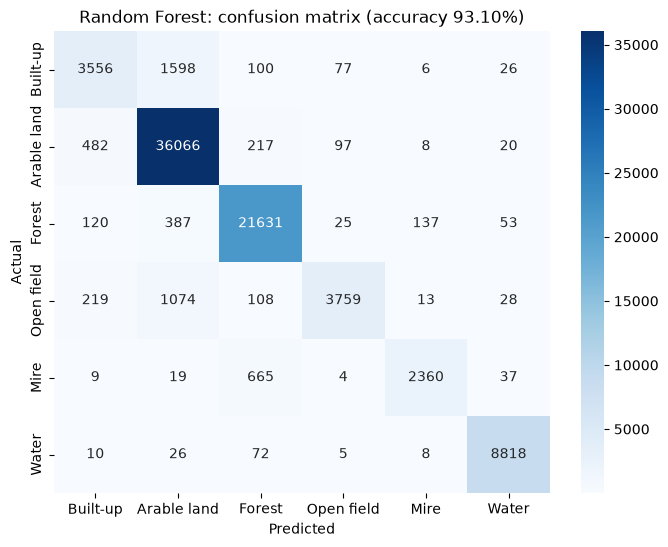

Accuracy: 93.10% | Precision: 92.33% | Recall: 84.67% | F1-score: 87.97%


In [17]:
# Predict the test set, compute the metrics and plot the confusion matrix
rf_scores = test_scores(rf_clf)
plot_evaluation(rf_scores, "Random Forest")

## Support Vector Machine (SVM)

The SVM pipeline is scaling, then band selection, then an SVM with an RBF kernel. Scaling is needed because the RBF kernel use distances between pixels, and without it the bands with the largest values would dominate. It does not affect which bands are selected.

I tune C and gamma on a log scale, and whether to use class weights to give the small classes more importance.

Since the SVM is slower to train and predict, I tune it on 10k pixels and train the final model on 30k pixels instead of all 327k.

### Hyperparameter tuning

In [18]:
# Pipeline with scaling first, then feature selection, then the SVM
svm_pipe = Pipeline([
    ("scale", StandardScaler()),                       # Scaling every band to mean 0 and standard deviation 1
    ("select", SelectKBest(f_classif)),
    ("svm", SVC(kernel="rbf", random_state=42)),       
])

# Search space for randomized search
svm_dist = {
    "select__k": randint(4, 11),               # number of bands kept
    "svm__C": loguniform(1e-1, 1e3),           # misclassification penalty
    "svm__gamma": loguniform(1e-3, 1e1),       # reach of each pixel
    "svm__class_weight": [None, "balanced"],   # upweight rare classes
}

# Random search to find the best hyperparameters
svm_search = RandomizedSearchCV(
    svm_pipe,
    svm_dist,
    n_iter=15,
    cv=skf,                                                      # stratified 5-fold CV
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},    # both are computed for every combination
    refit="f1_macro",                                            # the best combination is chosen on macro F1
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
svm_search.fit(svm_tune[features], svm_tune["class_en"])

# Best combination, its CV score and the bands it kept
print("Best parameters:", svm_search.best_params_)
print(f"Best CV macro F1: {svm_search.best_score_:.4f}")
print("Selected bands:", selected_bands(svm_search.best_estimator_))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters: {'select__k': 10, 'svm__C': np.float64(153.52246941973468), 'svm__class_weight': None, 'svm__gamma': np.float64(0.8471801418819978)}
Best CV macro F1: 0.7126
Selected bands: ['B2', 'B3', 'B4', 'B8', 'B5', 'B6', 'B7', 'B8A', 'B11', 'B12']


### Final model

In [19]:
# 30k stratified subsample of the training set
svm_train, _ = train_test_split(train, train_size=30000, stratify=train["class_en"], random_state=42)

# Best model from random search
svm_clf = clone(svm_search.best_estimator_)

# Train and time it
t0 = time.time()
svm_clf.fit(svm_train[features], svm_train["class_en"])
svm_fit_time = time.time() - t0
print(f"Training time: {svm_fit_time:.1f} s")

# Support vectors
print(f"Support vectors: {svm_clf.named_steps['svm'].n_support_.sum()}")

Training time: 8.7 s
Support vectors: 9283


### Test set evaluation

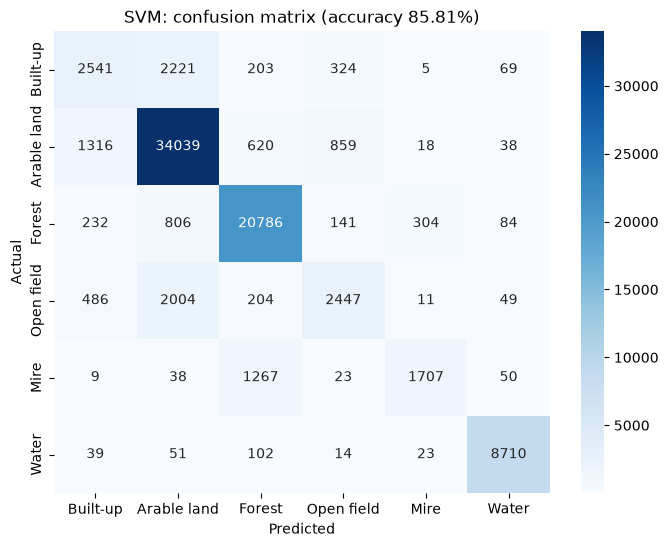

Accuracy: 85.81% | Precision: 79.19% | Recall: 72.05% | F1-score: 74.88%


In [20]:
# Predict the test set, compute the metrics and plot the confusion matrix
svm_scores = test_scores(svm_clf)
plot_evaluation(svm_scores, "SVM")

## K-Nearest Neighbours (KNN)

The KNN pipeline is the same as for the SVM, consisting of scaling, then band selection, then KNN. Scaling is needed because KNN finds neighbours by distance, and without it the bands with the largest values would dominate.

I tune the number of neighbours, whether closer neighbours get more weight, and the distance metric.

### Hyperparameter tuning

In [21]:
# Pipeline with scaling first, then feature selection, then KNN
knn_pipe = Pipeline([
    ("scale", StandardScaler()),                       # Scaling bands to mean 0 and standard deviation 1
    ("select", SelectKBest(f_classif)),
    ("knn", KNeighborsClassifier(n_jobs=-1)),          
])

# Search space. p=1 is Manhattan distance, p=2 is Euclidean distance;
# weights="distance" lets closer neighbours count more
knn_dist = {
    "select__k": randint(4, 11),               # number of bands kept
    "knn__n_neighbors": randint(1, 31),        # number of neighbours that vote
    "knn__weights": ["uniform", "distance"],   # with 'distance' closer neighbours count more
    "knn__p": [1, 2],                          # Manhattan or Euclidean
}

# Random search to find best hyperparameters
knn_search = RandomizedSearchCV(
    knn_pipe,
    knn_dist,
    n_iter=15,                                                   
    cv=skf,                                                      # stratified 5-fold CV
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},    # both are computed for every combination
    refit="f1_macro",                                            # the best combination is chosen on macro F1
    random_state=42,
    verbose=1,
)
knn_search.fit(tune[features], tune["class_en"])

# Best combination, its CV score and the bands it kept
print("Best parameters:", knn_search.best_params_)
print(f"Best CV macro F1: {knn_search.best_score_:.4f}")
print("Selected bands:", selected_bands(knn_search.best_estimator_))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters: {'knn__n_neighbors': 23, 'knn__p': 2, 'knn__weights': 'distance', 'select__k': 4}
Best CV macro F1: 0.7415
Selected bands: ['B6', 'B7', 'B8A', 'B11']


### Final model

In [22]:
# Best combination from the random search, trained on the full training set
knn_clf = clone(knn_search.best_estimator_)

# Train and time it
t0 = time.time()
knn_clf.fit(train[features], train["class_en"])
knn_fit_time = time.time() - t0
print(f"Training time: {knn_fit_time:.1f} s")

Training time: 0.1 s


### Test set evaluation

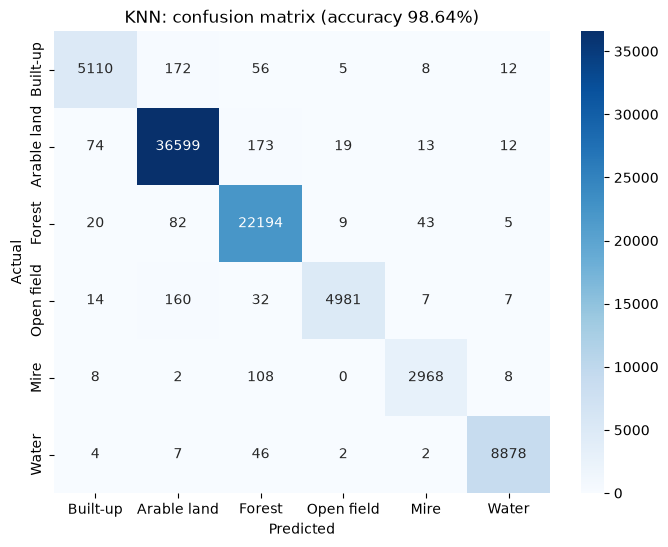

Accuracy: 98.64% | Precision: 98.52% | Recall: 97.47% | F1-score: 97.98%


In [23]:
# Predict the test set, compute the metrics and plot the confusion matrix
knn_scores = test_scores(knn_clf)
plot_evaluation(knn_scores, "KNN")

## Model comparison

### Test set results

In [24]:
# Comparison table, one row per model
comparison = pd.DataFrame({
    name: {
        **{k: v for k, v in scores.items() if k != "y_pred"},     # test metrics, without predictions
        "Best CV macro F1 (%)": search.best_score_ * 100,
        "Training pixels": n_train,
        "Training time (s)": fit_time,
        "Bands used": len(selected_bands(model)),
    }
    for name, scores, search, model, n_train, fit_time in [
        ("Random Forest", rf_scores, rf_search, rf_clf, len(train), rf_fit_time),
        ("SVM", svm_scores, svm_search, svm_clf, len(svm_train), svm_fit_time),
        ("KNN", knn_scores, knn_search, knn_clf, len(train), knn_fit_time),
    ]
}).T

# Bands kept by each model
for name, model in [("Random Forest", rf_clf), ("SVM", svm_clf), ("KNN", knn_clf)]:
    print(f"{name:14s} bands: {selected_bands(model)}")
comparison.round(2)

Random Forest  bands: ['B2', 'B3', 'B4', 'B8', 'B5', 'B6', 'B7', 'B8A', 'B11', 'B12']
SVM            bands: ['B2', 'B3', 'B4', 'B8', 'B5', 'B6', 'B7', 'B8A', 'B11', 'B12']
KNN            bands: ['B6', 'B7', 'B8A', 'B11']


,Accuracy,Precision,Recall,F1-score,Predict time test (s),Best CV macro F1 (%),Training pixels,Training time (s),Bands used
Random Forest,93.10,92.33,84.67,87.97,0.37,74.69,327357.0,48.87,10.0
SVM,85.81,79.19,72.05,74.88,18.39,71.26,30000.0,8.74,10.0
KNN,98.64,98.52,97.47,97.98,0.21,74.15,327357.0,0.13,4.0


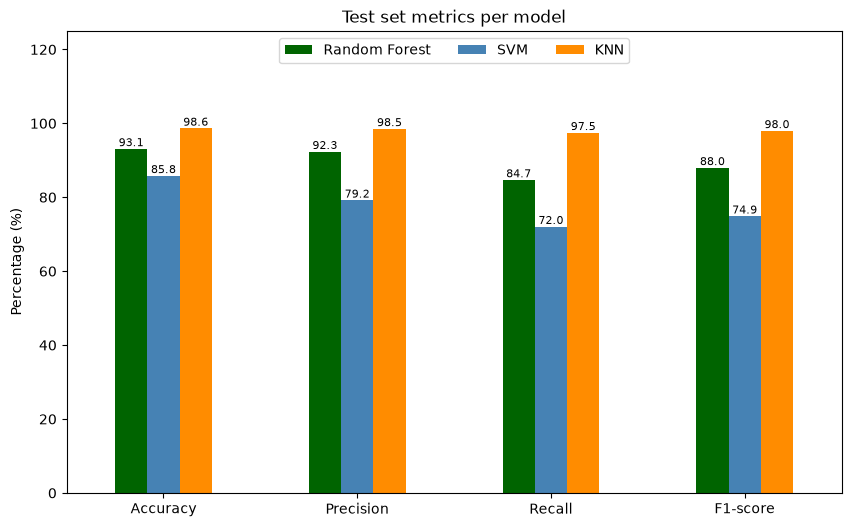

In [25]:
# Test metrics per model
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]

ax = comparison[metric_names].T.plot(kind="bar", figsize=(10, 6), rot=0, color=["darkgreen", "steelblue", "darkorange"])
ax.set_ylim(0, 125)                         
ax.set_ylabel("Percentage (%)")
ax.set_title("Test set metrics per model")
ax.legend(loc="upper center", ncol=3)

# Value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)
plt.show()

### Classified maps

To compare the models visually, all three classify the same 1000 x 1000 pixel window (10 x 10 km). I kept the window small because the SVM is slow to predict, and it takes about 3 minutes for these 1 million pixels.

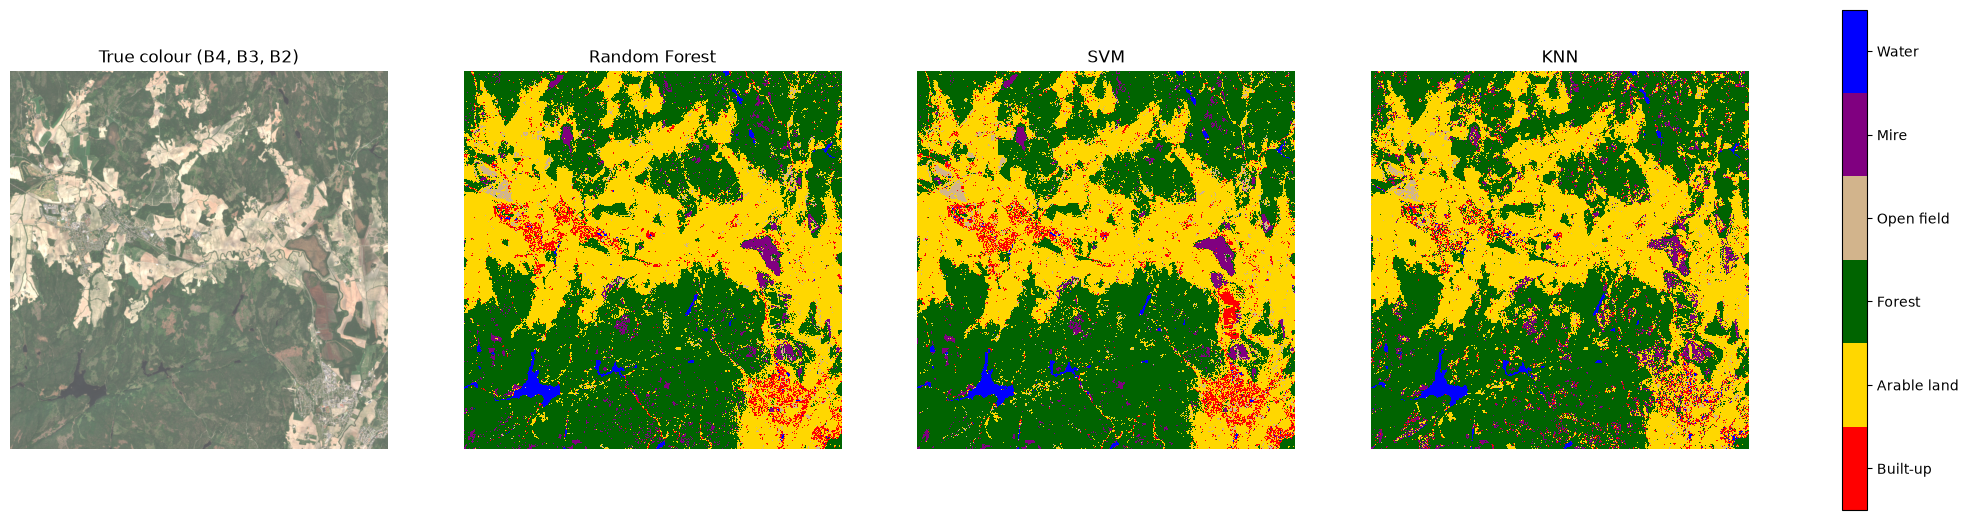

,Accuracy,Precision,Recall,F1-score,Predict time test (s),Best CV macro F1 (%),Training pixels,Training time (s),Bands used,Predict time window (s)
Random Forest,93.10,92.33,84.67,87.97,0.37,74.69,327357.0,48.87,10.0,2.51
SVM,85.81,79.19,72.05,74.88,18.39,71.26,30000.0,8.74,10.0,229.67
KNN,98.64,98.52,97.47,97.98,0.21,74.15,327357.0,0.13,4.0,2.64


In [26]:
# Window to classify, flattened to one row per pixel
win = dict(y=slice(5000, 6000), x=slice(3490, 4490))
sub = im.isel(**win).transpose("band", "y", "x").values    # (band, y, x)
n_bands, ny, nx = sub.shape

# One row per pixel, one column per band
flat_pixels = pd.DataFrame(sub.reshape(n_bands, -1).T, columns=features)

# Classify with each model and reshape back to map
maps = {}
for name, model in [("Random Forest", rf_clf), ("SVM", svm_clf), ("KNN", knn_clf)]:
    t0 = time.time()
    maps[name] = model.predict(flat_pixels).reshape(ny, nx)
    comparison.loc[name, "Predict time window (s)"] = time.time() - t0

# One colour per class, same order as classnames
cmap = ListedColormap(["red", "gold", "darkgreen", "tan", "purple", "blue"])

# True colour image, then the three classified maps
fig, axes = plt.subplots(1, 4, figsize=(24, 6.5))
axes[0].imshow(np.clip(sub[[2, 1, 0]].transpose(1, 2, 0) / 3000, 0, 1))   # bands 2, 1, 0 = B4, B3, B2
axes[0].set_title("True colour (B4, B3, B2)")
for ax, (name, class_map) in zip(axes[1:], maps.items()):
    # align each class with its color
    m = ax.imshow(class_map, cmap=cmap, vmin=-0.5, vmax=len(classnames) - 0.5, interpolation="nearest")
    ax.set_title(name)
for ax in axes:
    ax.axis("off")

# Shared color bar with class names
cbar = fig.colorbar(m, ax=axes, ticks=np.arange(len(classnames)), fraction=0.015)
cbar.ax.set_yticklabels(classnames)
plt.show()

# Comparison table with prediction time
comparison.round(2)

## Discussion

**Tuned models:** The Random Forest used 200 trees, max depth 30, 70 % of the bands per split, at least 3 pixels per leaf and no bootstrap. The SVM used C ≈ 154 and gamma ≈ 0.85 without class weights. KNN used 23 neighbours with distance weighting and Euclidean distance. The Random Forest and SVM kept all 10 bands, while KNN kept only 4 (B6, B7, B8A, B11), which fits since extra bands add noise to the distances. In the Random Forest, B11, B8A and B12 (short-wave and near-infrared) were the most important bands, and the visible bands the least.

**Test results:** KNN had the best macro F1 (98.0 %), followed by the Random Forest (88.0 %) and the SVM (74.9 %). The SVM is probably held back by being trained on only 30k pixels instead of 327k. All three models make the same kind of mistakes since Built-up and Open field are confused with Arable land, likely due to bare soil or sparse vegetation, Mire with Forest, possibly due to mires with trees. The Random Forest is slowest to train, and the SVM is by far the slowest to predict.

**Reliability of the scores:** The CV scores (71–75 % macro F1) are much lower than the test scores. Because the split was random, most test pixels have a near-identical training pixel from the same field, so the test scores are likely too optimistic. KNN benefits most from this. A split by area would give a more realistic estimate.

**Classified maps:** All maps show the same overall pattern as the true colour image. The Random Forest gives the cleanest map, with Built-up mainly in the visible settlements. The SVM marks a bare field right of the centre as Built-up, and KNN gives the noisiest map despite its high test scores, which supports the point above. All maps show salt-and-pepper noise, which a majority filter could reduce.

**Conclusion:** Overall, I think the Random Forest gives the best result, as it is accurate, fast to predict and gives the most realistic map.